In [3]:
#imports
import time
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets
from torchvision.transforms import v2
import matplotlib.pyplot as plt

# Use the GPU if one is available (in Colab: Runtime > Change runtime type > T4 GPU).
# Every model and every batch of data must be moved to this device with .to(device).
device = torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else "cpu"
print(f"Using {device} device")

# Fix the random seed so runs are repeatable (makes experiment comparisons fairer).
torch.manual_seed(42)

Using cuda device


In [4]:
# Where to store the dataset to avoid re-downloading it.
import os
try:
    from google.colab import drive
    drive.mount("/content/drive")
    DATA_ROOT = "/content/drive/MyDrive/datasets"
except Exception as e:
    print(f"Google Drive not available ({type(e).__name__}: {e}); using local storage.")
    DATA_ROOT = "data"

os.makedirs(DATA_ROOT, exist_ok=True)
print(f"Dataset folder: {DATA_ROOT}")

Google Drive not available (ModuleNotFoundError: No module named 'google'); using local storage.
Dataset folder: data


In [5]:
# Per-channel (R, G, B) mean and std of the CIFAR-10 training set.
# Normalize computes (pixel - mean) / std, so each channel is centered around 0 with
# roughly unit spread. Inputs on that scale make gradient descent train faster and more stably.
CIFAR10_MEAN = (0.4914, 0.4822, 0.4465)
CIFAR10_STD = (0.2470, 0.2435, 0.2616)

# ToImage -> tensor of shape [C, H, W]; ToDtype(scale=True) -> floats in [0, 1]; then Normalize.
# Kept as separate train/test transforms so data augmentation (Model 3) can later be
# added to train_transform ONLY. The test set should never be augmented.
train_transform = v2.Compose([
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(CIFAR10_MEAN, CIFAR10_STD),
])
test_transform = v2.Compose([
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(CIFAR10_MEAN, CIFAR10_STD),
])

# Download training data (skipped automatically if it's already in DATA_ROOT).
training_data = datasets.CIFAR10(
    root=DATA_ROOT,
    train=True,
    download=True,
    transform=train_transform,
)

# Download test data. Same files as above, so this one won't download again.
test_data = datasets.CIFAR10(
    root=DATA_ROOT,
    train=False,
    download=True,
    transform=test_transform,
)

classes = training_data.classes  # ['airplane', 'automobile', 'bird', ...]
print(f"Train: {len(training_data)} images, Test: {len(test_data)} images, {len(classes)} classes")

Train: 50000 images, Test: 10000 images, 10 classes


In [6]:
batch_size = 64

# Create data loaders.
# shuffle=True for training: the model sees batches in a new random order each epoch,
# so it can't learn anything from the order of the data. The test set doesn't need shuffling.
# num_workers loads batches in background processes so the GPU isn't left waiting.
# persistent_workers keeps those processes alive between epochs. pin_memory speeds up copying batches to the GPU.
loader_kwargs = dict(batch_size=batch_size, num_workers=2, persistent_workers=True,
                     pin_memory=torch.cuda.is_available())
train_dataloader = DataLoader(training_data, shuffle=True, **loader_kwargs)
test_dataloader = DataLoader(test_data, shuffle=False, **loader_kwargs)

for X, y in test_dataloader:
    print(f"Shape of X [N, C, H, W]: {X.shape}")
    print(f"Shape of y: {y.shape} {y.dtype}")
    break

Shape of X [N, C, H, W]: torch.Size([64, 3, 32, 32])
Shape of y: torch.Size([64]) torch.int64


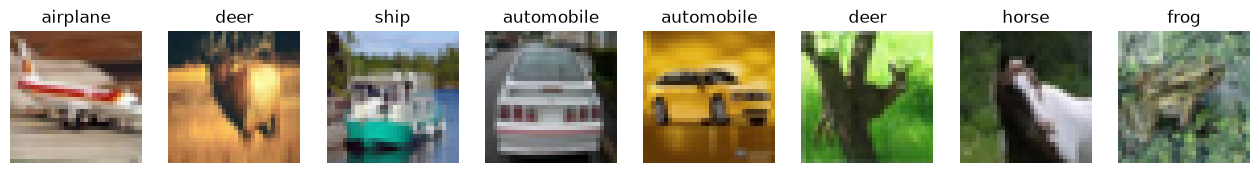

In [7]:
# Look at a few training images with their labels.
images, labels = next(iter(train_dataloader))
mean = torch.tensor(CIFAR10_MEAN).view(3, 1, 1)
std = torch.tensor(CIFAR10_STD).view(3, 1, 1)

fig, axes = plt.subplots(1, 8, figsize=(16, 2.5))
for ax, img, label in zip(axes, images, labels):
    img = (img * std + mean).clamp(0, 1)
    ax.imshow(img.permute(1, 2, 0))  # matplotlib expects [H, W, C], PyTorch uses [C, H, W]
    ax.set_title(classes[label])
    ax.axis("off")
plt.show()

In [8]:
# CrossEntropyLoss = softmax + negative log-likelihood, combined into one numerically stable step.
# It takes the raw model outputs ("logits"), so models should NOT end with a softmax layer.
loss_fn = nn.CrossEntropyLoss()


def train(dataloader, model, loss_fn, optimizer):
    """Run ONE epoch (one full pass over the training data). Returns (avg_loss, accuracy)."""
    model.train()  # turns ON training behavior for Dropout/BatchNorm (matters for Model 3)
    total_loss, correct, total = 0.0, 0, 0

    for X, y in dataloader:
        X, y = X.to(device), y.to(device)

        pred = model(X)          # 1. forward pass: logits of shape [batch, 10]
        loss = loss_fn(pred, y)  # 2. how wrong were the predictions?

        optimizer.zero_grad()    # 3. clear gradients left over from the previous batch
        loss.backward()          # 4. backprop: compute d(loss)/d(weight) for every weight
        optimizer.step()         # 5. nudge each weight against its gradient

        # Bookkeeping. loss.item() is the batch's mean loss, so weight it by batch size.
        total_loss += loss.item() * X.size(0)
        correct += (pred.argmax(dim=1) == y).sum().item()
        total += X.size(0)

    return total_loss / total, correct / total


def evaluate(dataloader, model, loss_fn):
    """Measure loss and accuracy WITHOUT updating weights. Returns (avg_loss, accuracy)."""
    model.eval()  # turns OFF Dropout and makes BatchNorm use its learned statistics
    total_loss, correct, total = 0.0, 0, 0

    with torch.no_grad():  # no gradients needed here, which saves memory and time
        for X, y in dataloader:
            X, y = X.to(device), y.to(device)
            pred = model(X)
            total_loss += loss_fn(pred, y).item() * X.size(0)
            correct += (pred.argmax(dim=1) == y).sum().item()
            total += X.size(0)

    return total_loss / total, correct / total


def fit(model, optimizer, epochs, train_dl=train_dataloader, test_dl=test_dataloader, scheduler=None):
    """Train for several epochs, evaluating after each one.
    scheduler (optional): a learning-rate scheduler, stepped once at the end of every epoch.
    Returns a history dict you can plot later and use to compare experiments."""
    history = {"train_loss": [], "train_acc": [], "test_loss": [], "test_acc": [], "lr": []}
    start = time.time()

    for epoch in range(epochs):
        lr = optimizer.param_groups[0]["lr"]  # learning rate used for this epoch
        train_loss, train_acc = train(train_dl, model, loss_fn, optimizer)
        test_loss, test_acc = evaluate(test_dl, model, loss_fn)
        if scheduler is not None:
            scheduler.step()  # adjust the learning rate for the next epoch

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["test_loss"].append(test_loss)
        history["test_acc"].append(test_acc)
        history["lr"].append(lr)

        print(f"Epoch {epoch + 1:>2}/{epochs} | lr {lr:.2e} | "
              f"train loss {train_loss:.4f}, acc {train_acc:.2%} | "
              f"test loss {test_loss:.4f}, acc {test_acc:.2%}")

    history["train_time_s"] = time.time() - start
    history["num_params"] = sum(p.numel() for p in model.parameters())
    print(f"Done in {history['train_time_s']:.1f}s, {history['num_params']:,} parameters")
    return history


def plot_history(histories):
    """Plot loss and accuracy curves. `histories` is a dict like {"MLP": hist1, "CNN": hist2}."""
    fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(12, 4))
    for name, h in histories.items():
        ax_loss.plot(h["train_loss"], label=f"{name} train")
        ax_loss.plot(h["test_loss"], "--", label=f"{name} test")
        ax_acc.plot(h["train_acc"], label=f"{name} train")
        ax_acc.plot(h["test_acc"], "--", label=f"{name} test")
    ax_loss.set(title="Loss", xlabel="Epoch")
    ax_acc.set(title="Accuracy", xlabel="Epoch")
    ax_loss.legend()
    ax_acc.legend()
    plt.show()

In [9]:
class MLP(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()                 # required: sets up nn.Module's internals
        self.flatten = nn.Flatten()        # [N, 3, 32, 32] -> [N, 3072]
        self.layers = nn.Sequential(
            nn.Linear(3 * 32 * 32, 512),   # 3072 inputs -> 512 hidden units
            nn.ReLU(),
            nn.Linear(512, 256),           # 512 -> 256
            nn.ReLU(),
            nn.Linear(256, num_classes),   # 256 -> 10 scores (logits), one per class
        )

    def forward(self, x):
        x = self.flatten(x)
        return self.layers(x)              # no softmax: CrossEntropyLoss handles it

MLP(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (layers): Sequential(
    (0): Linear(in_features=3072, out_features=512, bias=True)
    (1): ReLU()
    (2): Linear(in_features=512, out_features=256, bias=True)
    (3): ReLU()
    (4): Linear(in_features=256, out_features=10, bias=True)
  )
)
Epoch  1/10 | lr 1.00e-03 | train loss 1.6575, acc 41.19% | test loss 1.5151, acc 46.68%
Epoch  2/10 | lr 1.00e-03 | train loss 1.4640, acc 48.37% | test loss 1.4700, acc 48.33%
Epoch  3/10 | lr 1.00e-03 | train loss 1.3542, acc 52.16% | test loss 1.4194, acc 49.89%
Epoch  4/10 | lr 1.00e-03 | train loss 1.2823, acc 54.57% | test loss 1.3851, acc 51.63%
Epoch  5/10 | lr 1.00e-03 | train loss 1.2053, acc 57.38% | test loss 1.4328, acc 50.83%
Epoch  6/10 | lr 1.00e-03 | train loss 1.1392, acc 59.47% | test loss 1.4042, acc 52.47%
Epoch  7/10 | lr 1.00e-03 | train loss 1.0835, acc 61.64% | test loss 1.4027, acc 53.11%
Epoch  8/10 | lr 1.00e-03 | train loss 1.0150, acc 64.00% | test loss 1.4806, 

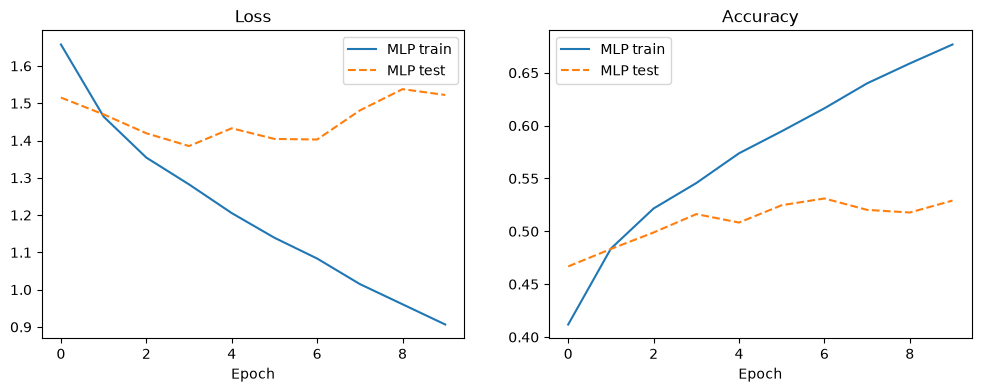

In [10]:
mlp = MLP().to(device)
print(mlp)  # shows the layer structure
optimizer = torch.optim.Adam(mlp.parameters(), lr=1e-3)
mlp_hist = fit(mlp, optimizer, epochs=10)
plot_history({"MLP": mlp_hist})


In [11]:
class SimpleCNN(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        # Feature extractor: learns local patterns (edges -> textures -> parts).
        # Conv2d(in_channels, out_channels, kernel_size):
        #   - in_channels:  how many channels come in (3 for RGB at the start)
        #   - out_channels: how many different 3x3 filters to learn; each one makes its own output "feature map"
        #   - padding=1 adds a 1-pixel border so a 3x3 filter keeps height/width the same
        # MaxPool2d(2) keeps the largest value in each 2x2 window -> halves height and width.
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),   # [N, 3, 32, 32]  -> [N, 32, 32, 32]
            nn.ReLU(),
            nn.MaxPool2d(2),                              # [N, 32, 32, 32] -> [N, 32, 16, 16]

            nn.Conv2d(32, 64, kernel_size=3, padding=1),  # [N, 32, 16, 16] -> [N, 64, 16, 16]
            nn.ReLU(),
            nn.MaxPool2d(2),                              # [N, 64, 16, 16] -> [N, 64, 8, 8]
        )
        # Classifier: same idea as the MLP, but its input is 64 learned feature maps
        # of size 8x8 instead of raw pixels.
        self.classifier = nn.Sequential(
            nn.Flatten(),                                 # [N, 64, 8, 8] -> [N, 4096]
            nn.Linear(64 * 8 * 8, 256),
            nn.ReLU(),
            nn.Linear(256, num_classes),                  # logits, no softmax
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)

In [12]:
# Shape check: push one fake image through the network layer by layer and print each output shape.
# This is the easiest way to work out (or debug) the input size of the first Linear layer.
x = torch.randn(1, 3, 32, 32)  # a batch of 1 random "image"
for layer in SimpleCNN().features:
    x = layer(x)
    print(f"{layer.__class__.__name__:>10} -> {tuple(x.shape)}")
print(f"Flattened size: {x.numel()}  (must match the first nn.Linear's input)")

    Conv2d -> (1, 32, 32, 32)
      ReLU -> (1, 32, 32, 32)
 MaxPool2d -> (1, 32, 16, 16)
    Conv2d -> (1, 64, 16, 16)
      ReLU -> (1, 64, 16, 16)
 MaxPool2d -> (1, 64, 8, 8)
Flattened size: 4096  (must match the first nn.Linear's input)


SimpleCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=4096, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=10, bias=True)
  )
)
Epoch  1/10 | lr 1.00e-03 | train loss 1.2617, acc 54.72% | test loss 1.0309, acc 63.79%
Epoch  2/10 | lr 1.00e-03 | train loss 0.8776, acc 69.07% | test loss 0.9286, acc 67.33%
Epoch  3/10 | lr 1.00e-03 | train loss 0.7086, acc 74.91% | test loss 0.8251, acc 71.70%
Epoch  4/10 | lr 1.00e-03 | train loss 0.5617, acc 80.21% | test loss 0.8081, acc 73.43%
Epoch  5/10 | lr 1.00e-03 | train loss

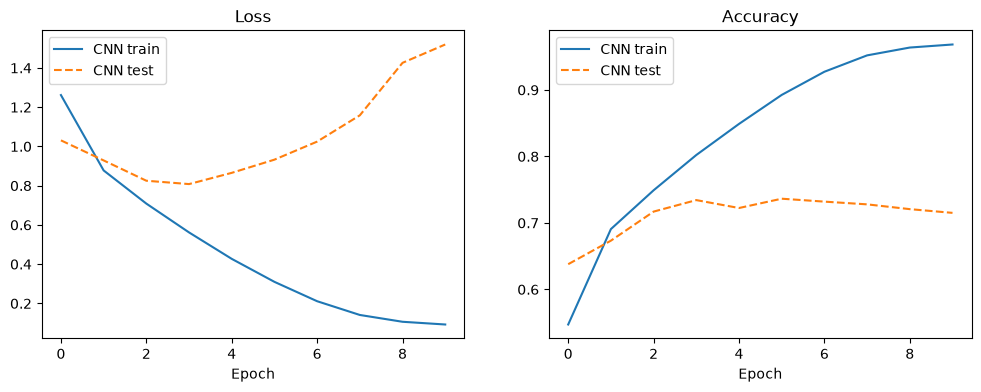

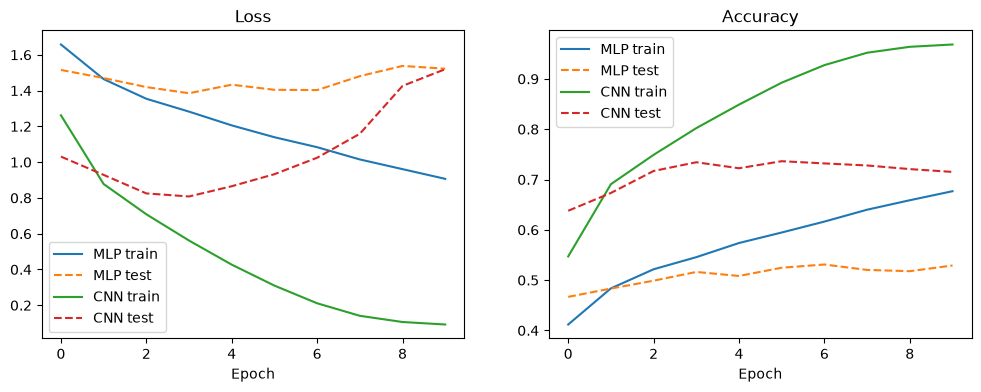

MLP: 1,707,274 params, best test acc 53.11%
CNN: 1,070,794 params, best test acc 73.64%


In [13]:
torch.manual_seed(42)  # same starting point as the MLP run, so the comparison is fair
cnn = SimpleCNN().to(device)
print(cnn)
optimizer = torch.optim.Adam(cnn.parameters(), lr=1e-3)  # same optimizer/lr/epochs as the MLP
cnn_hist = fit(cnn, optimizer, epochs=10)

plot_history({"CNN": cnn_hist})
plot_history({"MLP": mlp_hist, "CNN": cnn_hist})  # side-by-side comparison

print(f"MLP: {mlp_hist['num_params']:,} params, best test acc {max(mlp_hist['test_acc']):.2%}")
print(f"CNN: {cnn_hist['num_params']:,} params, best test acc {max(cnn_hist['test_acc']):.2%}")

In [14]:
# Data augmentation for the deep CNN.
# Each epoch, every training image gets a random crop (pad by 4 px, crop back to 32x32 -> small shifts)
# and a 50% chance of a horizontal flip. The model never sees exactly the same image twice, so it
# can't just memorize the training set (the problem both earlier models had).
# Only the TRAINING data is augmented. The test set keeps test_transform so its scores stay comparable.
aug_train_transform = v2.Compose([
    v2.ToImage(),
    v2.RandomCrop(32, padding=4),
    v2.RandomHorizontalFlip(),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(CIFAR10_MEAN, CIFAR10_STD),
])

# Same files on disk as training_data (no new download), just with the augmenting transform.
aug_training_data = datasets.CIFAR10(root=DATA_ROOT, train=True, download=True, transform=aug_train_transform)
aug_train_dataloader = DataLoader(aug_training_data, shuffle=True, **loader_kwargs)

In [15]:
def conv_block(in_channels, out_channels):
    """VGG-style block: two (Conv -> BatchNorm -> ReLU) layers, then MaxPool.
    Two stacked 3x3 convs "see" a 5x5 area with fewer weights than one 5x5 conv,
    plus an extra ReLU, so the block can learn more complex patterns."""
    return nn.Sequential(
        # bias=False because BatchNorm right after it has its own shift parameter (the bias would be redundant)
        nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1, bias=False),
        nn.BatchNorm2d(out_channels),  # normalize each channel over the batch -> stable, faster training
        nn.ReLU(),
        nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1, bias=False),
        nn.BatchNorm2d(out_channels),
        nn.ReLU(),
        nn.MaxPool2d(2),               # halve height and width
    )


class DeepCNN(nn.Module):
    # dropout defaults to 0.0 (OFF): the ablation experiments showed Dropout gave no benefit on top of
    # augmentation + BatchNorm ("No Dropout" scored +0.32% vs. the full model). The experiments cell
    # still passes dropout=0.5 explicitly to reproduce the original "Full Deep CNN".
    def __init__(self, num_classes=10, dropout=0.0):
        super().__init__()
        # Each block doubles the channels and halves the image size:
        # the network trades spatial detail for more (and more abstract) features.
        self.features = nn.Sequential(
            conv_block(3, 64),     # [N, 3, 32, 32]   -> [N, 64, 16, 16]
            conv_block(64, 128),   # [N, 64, 16, 16]  -> [N, 128, 8, 8]
            conv_block(128, 256),  # [N, 128, 8, 8]   -> [N, 256, 4, 4]
        )

        # With dropout > 0: randomly zero that fraction of values during training (off in eval mode).
        # With dropout = 0: nn.Identity() passes values through unchanged, i.e. no dropout layer at all.
        # (Identity keeps the layer positions the same, so saved weights load into either version.)
        def maybe_dropout():
            return nn.Dropout(dropout) if dropout > 0 else nn.Identity()

        self.classifier = nn.Sequential(
            nn.Flatten(),                  # [N, 256, 4, 4] -> [N, 4096]
            maybe_dropout(),
            nn.Linear(256 * 4 * 4, 512),
            nn.ReLU(),
            maybe_dropout(),
            nn.Linear(512, num_classes),   # logits, no softmax
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)


# Shape check, block by block (same idea as for SimpleCNN).
x = torch.randn(2, 3, 32, 32)  # batch of 2: BatchNorm needs more than 1 value per channel in train mode
for i, block in enumerate(DeepCNN().features, start=1):
    x = block(x)
    print(f"After block {i}: {tuple(x.shape)}")
print(f"Flattened size per image: {x[0].numel()}  (must match the first nn.Linear's input)")

After block 1: (2, 64, 16, 16)
After block 2: (2, 128, 8, 8)
After block 3: (2, 256, 4, 4)
Flattened size per image: 4096  (must match the first nn.Linear's input)


Loaded 7 saved run(s) from e:\GitHubRepos\ECE-8478-Advanced-Machine-Learning\Pytorch Onboarding\results\ablation_results.json

=== Full Deep CNN: already done, loaded from file ===

=== No augmentation: already done, loaded from file ===

=== No BatchNorm: already done, loaded from file ===

=== No Dropout: already done, loaded from file ===

=== No LR schedule: already done, loaded from file ===

=== Shallower (1 conv/block): already done, loaded from file ===

=== Short training (10 ep): already done, loaded from file ===

Variant                        Params  Epochs  Best test  vs full  Final train  Final test     Gap     Time
-----------------------------------------------------------------------------------------------------------
No Dropout                  3,249,098      30     90.61%   +0.32%       97.78%      90.61%   +7.2%    3.3 m
Full Deep CNN               3,249,098      30     90.29%   +0.00%       94.38%      90.23%   +4.2%    3.4 m
No LR schedule              3,249,098

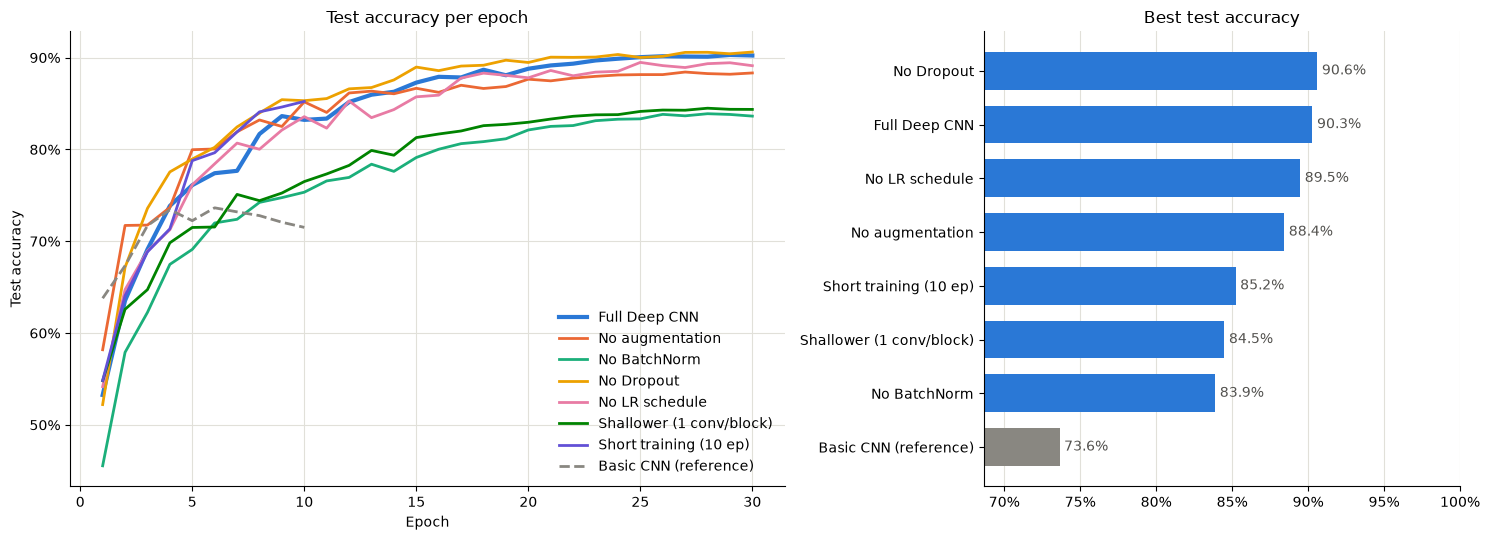

In [16]:
# ======================= EXPERIMENTS: ablation study =======================
# The Deep CNN differs from the Basic CNN in six ways at once. To see what each change contributes,
# train the FULL Deep CNN with exactly ONE improvement removed per run ("leave-one-out" ablation).
#
# Every finished run is saved to results/ablation_results.json (next to the data folder). If the
# kernel crashes or you stop it, just re-run this cell: finished variants are loaded from the file
# instead of being trained again. Delete that file to retrain everything from scratch.
# The full Deep CNN's trained weights are also saved, so the final Deep CNN cell below can reuse them.
import json

ABLATION_EPOCHS = 30   # epochs for every variant (except the "short training" ablation)
RESULTS_DIR = os.path.join(os.path.dirname(os.path.abspath(DATA_ROOT)), "results")
RESULTS_PATH = os.path.join(RESULTS_DIR, "ablation_results.json")
FULL_WEIGHTS_PATH = os.path.join(RESULTS_DIR, "deep_cnn_full.pt")


class AblationCNN(nn.Module):
    """DeepCNN with each architectural improvement switchable.
    With the default arguments it has exactly the same layers as DeepCNN."""

    def __init__(self, num_classes=10, use_batchnorm=True, dropout=0.5, convs_per_block=2):
        super().__init__()
        layers, in_ch = [], 3
        for out_ch in (64, 128, 256):              # same 3 blocks: 32x32 -> 16 -> 8 -> 4
            for _ in range(convs_per_block):
                # Without BatchNorm, the conv needs its own bias again.
                layers.append(nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1, bias=not use_batchnorm))
                if use_batchnorm:
                    layers.append(nn.BatchNorm2d(out_ch))
                layers.append(nn.ReLU())
                in_ch = out_ch
            layers.append(nn.MaxPool2d(2))
        self.features = nn.Sequential(*layers)
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(dropout),                   # Dropout(0.0) does nothing = "no dropout"
            nn.Linear(256 * 4 * 4, 512),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(512, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


# The complete Deep CNN recipe. Each variant below overrides ONE setting.
FULL_CONFIG = dict(use_batchnorm=True, dropout=0.5, convs_per_block=2,
                   augment=True, scheduler=True, epochs=ABLATION_EPOCHS)
VARIANTS = {
    "Full Deep CNN":            {},
    "No augmentation":          {"augment": False},
    "No BatchNorm":             {"use_batchnorm": False},
    "No Dropout":               {"dropout": 0.0},
    "No LR schedule":           {"scheduler": False},       # constant lr = 1e-3 the whole run
    "Shallower (1 conv/block)": {"convs_per_block": 1},     # 3 conv layers instead of 6
    "Short training (10 ep)":   {"epochs": 10},             # same epoch count as the Basic CNN
}

# Load runs finished earlier (if any).
try:
    with open(RESULTS_PATH) as f:
        results = json.load(f)
    print(f"Loaded {len(results)} saved run(s) from {RESULTS_PATH}")
except FileNotFoundError:
    results = {}

for name, overrides in VARIANTS.items():
    cfg = {**FULL_CONFIG, **overrides}
    if name in results and results[name]["config"] == cfg:
        print(f"\n=== {name}: already done, loaded from file ===")
        continue

    print(f"\n=== {name} === {overrides or '(all improvements)'}")
    torch.manual_seed(42)  # identical starting weights for every variant -> fair comparison
    if name == "Full Deep CNN":
        # The real DeepCNN class (same layers as AblationCNN's defaults), so its saved weights
        # can be loaded straight into DeepCNN() in the final cell.
        model = DeepCNN(dropout=cfg["dropout"]).to(device)
    else:
        model = AblationCNN(use_batchnorm=cfg["use_batchnorm"], dropout=cfg["dropout"],
                            convs_per_block=cfg["convs_per_block"]).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    scheduler = (torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=cfg["epochs"])
                 if cfg["scheduler"] else None)
    hist = fit(model, optimizer, epochs=cfg["epochs"],
               train_dl=aug_train_dataloader if cfg["augment"] else train_dataloader,
               scheduler=scheduler)

    # Save after EVERY run so progress survives a crash or a stopped kernel.
    os.makedirs(RESULTS_DIR, exist_ok=True)
    if name == "Full Deep CNN":
        torch.save(model.state_dict(), FULL_WEIGHTS_PATH)
    results[name] = {"config": cfg, "history": hist}
    with open(RESULTS_PATH, "w") as f:
        json.dump(results, f)

    del model, optimizer, scheduler
    if torch.cuda.is_available():
        torch.cuda.empty_cache()  # free GPU memory before the next variant

# ---------------------------- Comparison table ----------------------------
# "Gap" = final train acc - final test acc: a large gap means overfitting.
# (For augmented runs, train acc is measured on augmented images with Dropout on, so it reads LOW;
#  a small or negative gap there is expected.)
full_best = max(results["Full Deep CNN"]["history"]["test_acc"])
rows = [(name, results[name]["history"]) for name in VARIANTS]
if "cnn_hist" in globals():
    rows.append(("Basic CNN (reference)", cnn_hist))

print(f"\n{'Variant':<26}{'Params':>11}{'Epochs':>8}{'Best test':>11}{'vs full':>9}"
      f"{'Final train':>13}{'Final test':>12}{'Gap':>8}{'Time':>9}")
print("-" * 107)
for name, h in sorted(rows, key=lambda r: -max(r[1]["test_acc"])):
    best = max(h["test_acc"])
    gap = h["train_acc"][-1] - h["test_acc"][-1]
    print(f"{name:<26}{h['num_params']:>11,}{len(h['test_acc']):>8}{best:>11.2%}"
          f"{(best - full_best) * 100:>+8.2f}%{h['train_acc'][-1]:>13.2%}{h['test_acc'][-1]:>12.2%}"
          f"{gap * 100:>+7.1f}%{h['train_time_s'] / 60:>7.1f} m")

# --------------------------------- Plots ----------------------------------
# Fixed color per variant (same order as VARIANTS), so each variant keeps its color between runs.
SERIES_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6"]
MUTED, GRID, INK = "#898781", "#e1e0d9", "#52514e"

fig, (ax_curve, ax_bar) = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={"width_ratios": [3, 2]})

# Left: test accuracy per epoch for every variant.
for color, name in zip(SERIES_COLORS, VARIANTS):
    acc = results[name]["history"]["test_acc"]
    ax_curve.plot(range(1, len(acc) + 1), acc, color=color,
                  linewidth=3 if name == "Full Deep CNN" else 2, label=name)
if "cnn_hist" in globals():
    ax_curve.plot(range(1, len(cnn_hist["test_acc"]) + 1), cnn_hist["test_acc"],
                  color=MUTED, linewidth=2, linestyle="--", label="Basic CNN (reference)")
ax_curve.set(title="Test accuracy per epoch", xlabel="Epoch", ylabel="Test accuracy")
ax_curve.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax_curve.grid(True, color=GRID, linewidth=0.8)
ax_curve.legend(loc="lower right", frameon=False)

# Right: best test accuracy per variant, sorted, with the value printed on each bar.
ranked = sorted(rows, key=lambda r: max(r[1]["test_acc"]))
names = [r[0] for r in ranked]
bests = [max(r[1]["test_acc"]) for r in ranked]
bar_colors = [MUTED if n == "Basic CNN (reference)" else "#2a78d6" for n in names]
bars = ax_bar.barh(names, bests, color=bar_colors, height=0.7)
for bar, val in zip(bars, bests):
    ax_bar.text(val + 0.003, bar.get_y() + bar.get_height() / 2, f"{val:.1%}", va="center", color=INK)
ax_bar.set(title="Best test accuracy", xlim=(min(bests) - 0.05, 1.0))
ax_bar.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax_bar.grid(True, axis="x", color=GRID, linewidth=0.8)
ax_bar.set_axisbelow(True)

for ax in (ax_curve, ax_bar):
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
plt.tight_layout()
plt.show()

DeepCNN(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU()
      (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (5): ReLU()
      (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): Sequential(
      (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU()
      (3): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (5)

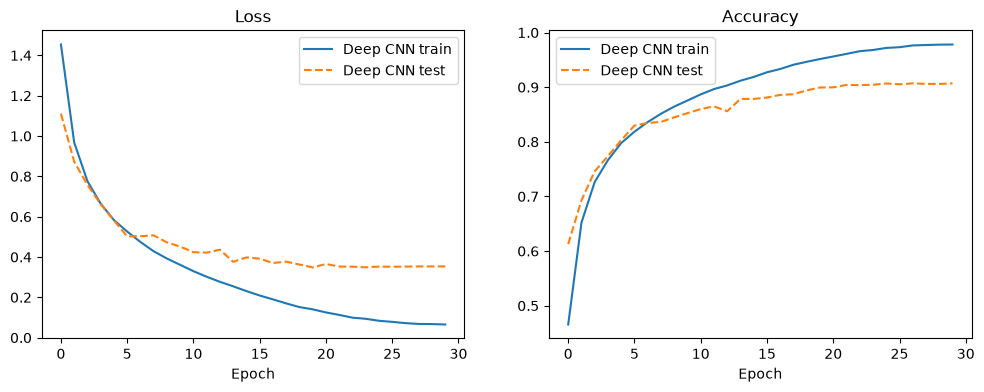

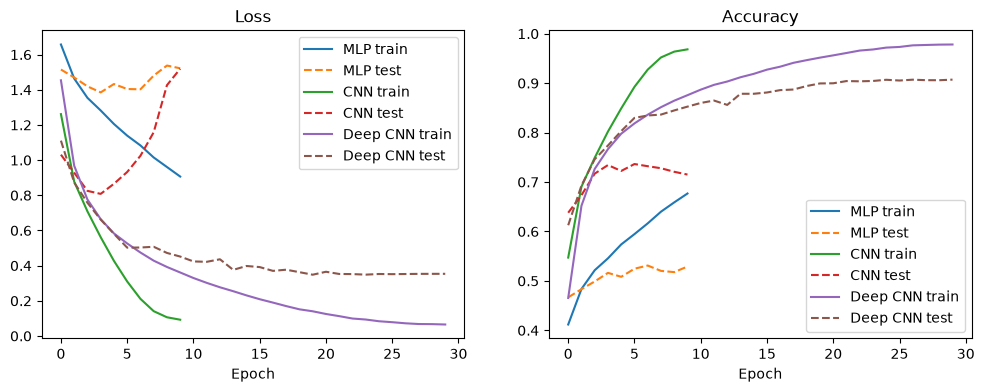

Model           Params  Epochs  Best test acc  Final test acc  Time (s)
MLP          1,707,274      10         53.11%          52.91%        40
CNN          1,070,794      10         73.64%          71.51%        41
Deep CNN     3,249,098      30         90.71%          90.71%       181


In [17]:
deep_epochs = 30   # 3x the earlier models: augmentation keeps it from overfitting, so longer training pays off
deep_dropout = 0.0  # no Dropout: the experiments above showed it didn't help (see "No Dropout" vs "Full Deep CNN")

# The experiments cell can save a trained Deep CNN's weights + history. Reuse them only if that run
# used exactly this recipe (same epochs AND same dropout); otherwise train from scratch here.
# The saved "Full Deep CNN" run used dropout=0.5, so with deep_dropout = 0.0 this cell retrains.
REUSE_ABLATION_RUN = False

torch.manual_seed(42)
deep_cnn = DeepCNN(dropout=deep_dropout).to(device)
print(deep_cnn)

full_run = globals().get("results", {}).get("Full Deep CNN")
if (REUSE_ABLATION_RUN and full_run and full_run["config"]["epochs"] == deep_epochs
        and full_run["config"]["dropout"] == deep_dropout and os.path.exists(FULL_WEIGHTS_PATH)):
    deep_cnn.load_state_dict(torch.load(FULL_WEIGHTS_PATH, map_location=device))
    deep_hist = full_run["history"]
    test_loss, test_acc = evaluate(test_dataloader, deep_cnn, loss_fn)  # confirm the loaded weights
    print(f"Loaded trained weights from {FULL_WEIGHTS_PATH}: test loss {test_loss:.4f}, acc {test_acc:.2%}")
else:
    optimizer = torch.optim.Adam(deep_cnn.parameters(), lr=1e-3)  # same optimizer/lr as the other models

    # Cosine annealing: lower the learning rate smoothly from 1e-3 toward 0 over the whole run.
    # Big steps early to make fast progress, tiny steps at the end to settle into a good minimum.
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=deep_epochs)

    deep_hist = fit(deep_cnn, optimizer, epochs=deep_epochs,
                    train_dl=aug_train_dataloader,  # augmented training data
                    scheduler=scheduler)

plot_history({"Deep CNN": deep_hist})
plot_history({"MLP": mlp_hist, "CNN": cnn_hist, "Deep CNN": deep_hist})

# Summary table for the write-up.
print(f"{'Model':<10}{'Params':>12}{'Epochs':>8}{'Best test acc':>15}{'Final test acc':>16}{'Time (s)':>10}")
for name, h in {"MLP": mlp_hist, "CNN": cnn_hist, "Deep CNN": deep_hist}.items():
    print(f"{name:<10}{h['num_params']:>12,}{len(h['test_acc']):>8}"
          f"{max(h['test_acc']):>15.2%}{h['test_acc'][-1]:>16.2%}{h['train_time_s']:>10.0f}")